# Analyse exploratoire (EDA) — Dataset Prostate (Stamey et al., 1989)

**Objectif du projet :** peut-on prédire la nature/gravité d'un cancer de la prostate à partir d'analyses de sang (PSA) et de facteurs cliniques, afin d'éviter des biopsies inutiles ?

**Plan de l'EDA**
1. Chargement et description des variables
2. Qualité des données (types, valeurs manquantes, doublons, valeurs « plancher »)
3. Analyse univariée
4. Analyse bivariée et corrélations
5. Choix de la variable cible
6. Valeurs aberrantes
7. Vérification du découpage train/test
8. Conclusions et pistes pour la modélisation

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.precision", 3)

## 1. Chargement et description des variables

In [2]:
df = pd.read_csv("../data/prostate.csv")
print("Dimensions :", df.shape)
df.head()

Dimensions : (97, 10)


,lcavol,lweight,age,lbph,svi,lcp,gleason,pgg45,lpsa,train
0,-0.580,2.769,50,-1.386,0,-1.386,6,0,-0.431,True
1,-0.994,3.320,58,-1.386,0,-1.386,6,0,-0.163,True
2,-0.511,2.691,74,-1.386,0,-1.386,7,20,-0.163,True
3,-1.204,3.283,58,-1.386,0,-1.386,6,0,-0.163,True
4,0.751,3.432,62,-1.386,0,-1.386,6,0,0.372,True


| Variable | Signification | Type |
|---|---|---|
| `lcavol` | log du volume tumoral (cm³) | continue |
| `lweight` | log du poids de la prostate (g) | continue |
| `age` | âge du patient (années) | discrète |
| `lbph` | log de la quantité d'hyperplasie bénigne de la prostate (cm²) | continue |
| `svi` | invasion des vésicules séminales (0 = non, 1 = oui) | binaire |
| `lcp` | log de la pénétration capsulaire (cm) | continue |
| `gleason` | score de Gleason (agressivité histologique, 6 à 10) | ordinale |
| `pgg45` | % de grades de Gleason 4 ou 5 | discrète (0–100) |
| `lpsa` | **log de l'antigène prostatique spécifique (PSA)** — l'analyse de sang | continue |
| `train` | indicateur du découpage train/test d'origine | booléen |

> ⚠️ **Point essentiel :** les 97 patients de cette étude ont **tous** un cancer de la prostate confirmé (ils ont subi une prostatectomie radicale). Il n'y a donc **pas de patients sains ni de variable « bénin / malin »** dans les données. Nous y revenons en section 5.

## 2. Qualité des données

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 97 entries, 0 to 96
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   lcavol   97 non-null     float64
 1   lweight  97 non-null     float64
 2   age      97 non-null     int64  
 3   lbph     97 non-null     float64
 4   svi      97 non-null     int64  
 5   lcp      97 non-null     float64
 6   gleason  97 non-null     int64  
 7   pgg45    97 non-null     int64  
 8   lpsa     97 non-null     float64
 9   train    97 non-null     bool   
dtypes: bool(1), float64(5), int64(4)
memory usage: 7.0 KB


In [4]:
print("Valeurs manquantes par colonne :")
print(df.isna().sum())
print("\nNombre de doublons :", df.duplicated().sum())

Valeurs manquantes par colonne :
lcavol     0
lweight    0
age        0
lbph       0
svi        0
lcp        0
gleason    0
pgg45      0
lpsa       0
train      0
dtype: int64

Nombre de doublons : 0


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
lcavol,97.0,1.350,1.179,-1.347,0.513,1.447,2.127,3.821
lweight,97.0,3.629,0.428,2.375,3.376,3.623,3.876,4.780
age,97.0,63.866,7.445,41.000,60.000,65.000,68.000,79.000
lbph,97.0,0.100,1.451,-1.386,-1.386,0.300,1.558,2.326
svi,97.0,0.216,0.414,0.000,0.000,0.000,0.000,1.000
lcp,97.0,-0.179,1.398,-1.386,-1.386,-0.799,1.179,2.904
gleason,97.0,6.753,0.722,6.000,6.000,7.000,7.000,9.000
pgg45,97.0,24.381,28.204,0.000,0.000,15.000,40.000,100.000
lpsa,97.0,2.478,1.154,-0.431,1.732,2.592,3.056,5.583


### Valeurs « plancher » dans `lbph` et `lcp`
Le minimum de `lbph` et `lcp` vaut exactement −1,386 = log(0,25). Les auteurs ont remplacé les valeurs nulles (absence d'hyperplasie / de pénétration capsulaire) par 0,25 avant le log. Ce ne sont donc pas de vraies mesures mais des **zéros codés**.

In [6]:
plancher = np.log(0.25)
for col in ["lbph", "lcp"]:
    n = np.isclose(df[col], plancher).sum()
    print(f"{col}: {n} valeurs = log(0.25)  ({n/len(df):.0%})")
print(f"pgg45: {(df.pgg45 == 0).sum()} valeurs = 0  ({(df.pgg45 == 0).mean():.0%})")

lbph: 43 valeurs = log(0.25)  (44%)
lcp: 45 valeurs = log(0.25)  (46%)
pgg45: 35 valeurs = 0  (36%)


➡️ Près de la moitié des patients sont au plancher pour `lbph` et `lcp`. Pour la modélisation, on pourra ajouter des indicateurs binaires (`lbph_present`, `lcp_present`).

## 3. Analyse univariée
### 3.1 Variables continues

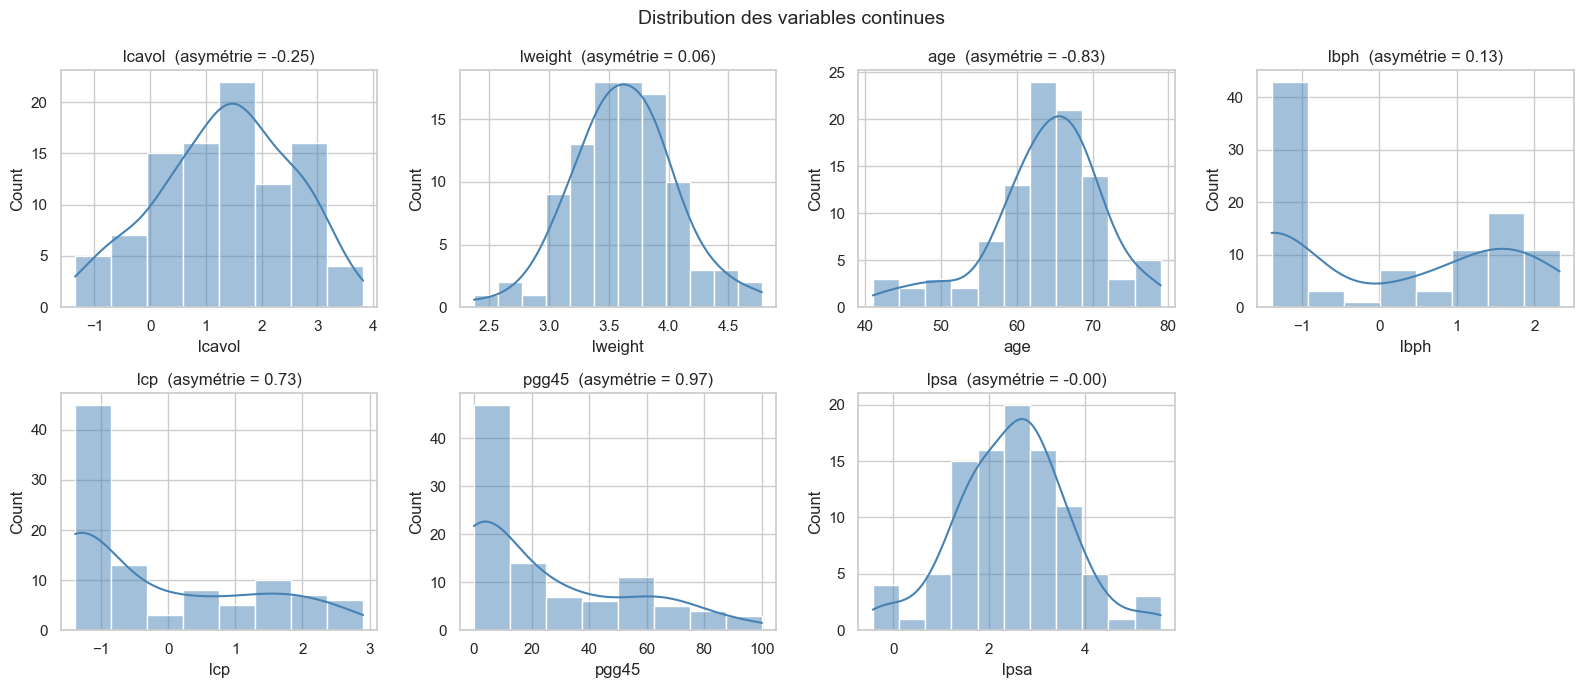

In [7]:
continues = ["lcavol", "lweight", "age", "lbph", "lcp", "pgg45", "lpsa"]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, continues):
    sns.histplot(df[col], kde=True, ax=ax, color="steelblue")
    ax.set_title(f"{col}  (asymétrie = {df[col].skew():.2f})")
axes.flat[-1].axis("off")
plt.suptitle("Distribution des variables continues", fontsize=14)
plt.tight_layout()
plt.show()

In [8]:
# Test de normalité de Shapiro-Wilk
res = []
for col in continues:
    w, p = stats.shapiro(df[col])
    res.append({"variable": col, "W": w, "p-value": p, "normale (α=5%)": p > 0.05})
pd.DataFrame(res).set_index("variable")

,W,p-value,normale (α=5%)
variable,,,
lcavol,0.983,2.414e-01,True
lweight,0.994,9.290e-01,True
age,0.947,6.376e-04,False
lbph,0.794,2.454e-10,False
lcp,0.806,5.842e-10,False
pgg45,0.823,2.065e-09,False
lpsa,0.984,3.087e-01,True


**Observations attendues :**
- `lpsa` et `lcavol` sont proches d'une loi normale grâce à la transformation log.
- `lbph`, `lcp`, `pgg45` sont bimodales / très asymétriques à cause des zéros codés.
- `age` est légèrement asymétrique à gauche (quelques patients jeunes).

### 3.2 Variables catégorielles

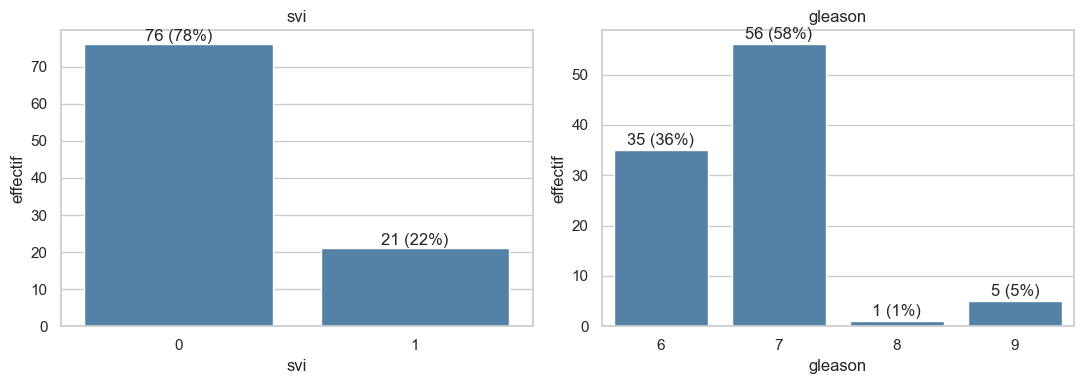

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col in zip(axes, ["svi", "gleason"]):
    vc = df[col].value_counts().sort_index()
    sns.barplot(x=vc.index.astype(str), y=vc.values, ax=ax, color="steelblue")
    for i, v in enumerate(vc.values):
        ax.text(i, v + 1, f"{v} ({v/len(df):.0%})", ha="center")
    ax.set_title(col); ax.set_ylabel("effectif")
plt.tight_layout()
plt.show()

- `svi` : déséquilibré (≈ 78 % de 0, 22 % de 1).
- `gleason` : quasi uniquement 6 ou 7 ; seulement 6 patients à 8 ou 9 → on regroupera en « ≤ 6 » vs « ≥ 7 ».

## 4. Analyse bivariée
### 4.1 Matrice de corrélation

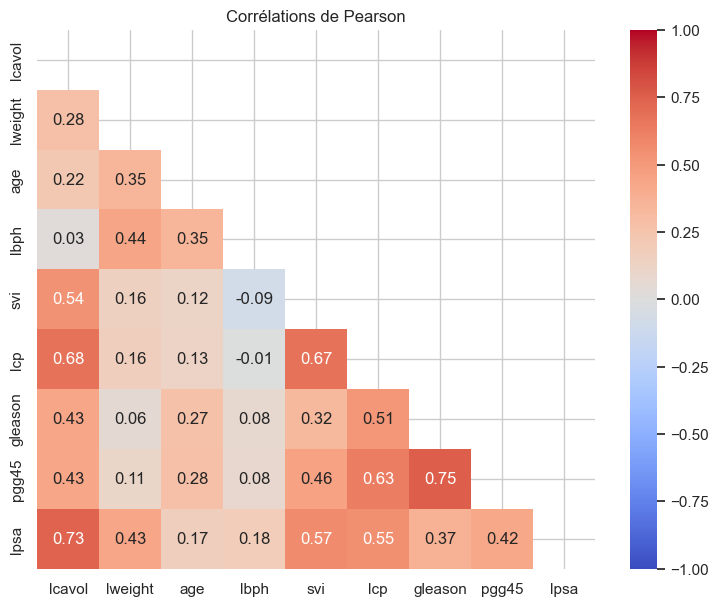

In [10]:
num = df.drop(columns="train")
corr = num.corr(method="pearson")
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(9, 7))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Corrélations de Pearson")
plt.show()

In [11]:
corr["lpsa"].drop("lpsa").sort_values(ascending=False).to_frame("corr. avec lpsa")

,corr. avec lpsa
lcavol,0.734
svi,0.566
lcp,0.549
lweight,0.433
pgg45,0.422
gleason,0.369
lbph,0.180
age,0.170


- `lcavol` (volume tumoral) est le meilleur corrélat du PSA (≈ 0,73), puis `svi` et `lcp`.
- Fortes corrélations entre prédicteurs : `gleason`–`pgg45` (≈ 0,75), `lcavol`–`lcp` (≈ 0,68), `svi`–`lcp` (≈ 0,67) → **multicolinéarité** à surveiller (régularisation Ridge/Lasso, ou VIF).

### 4.2 Nuage de points croisés

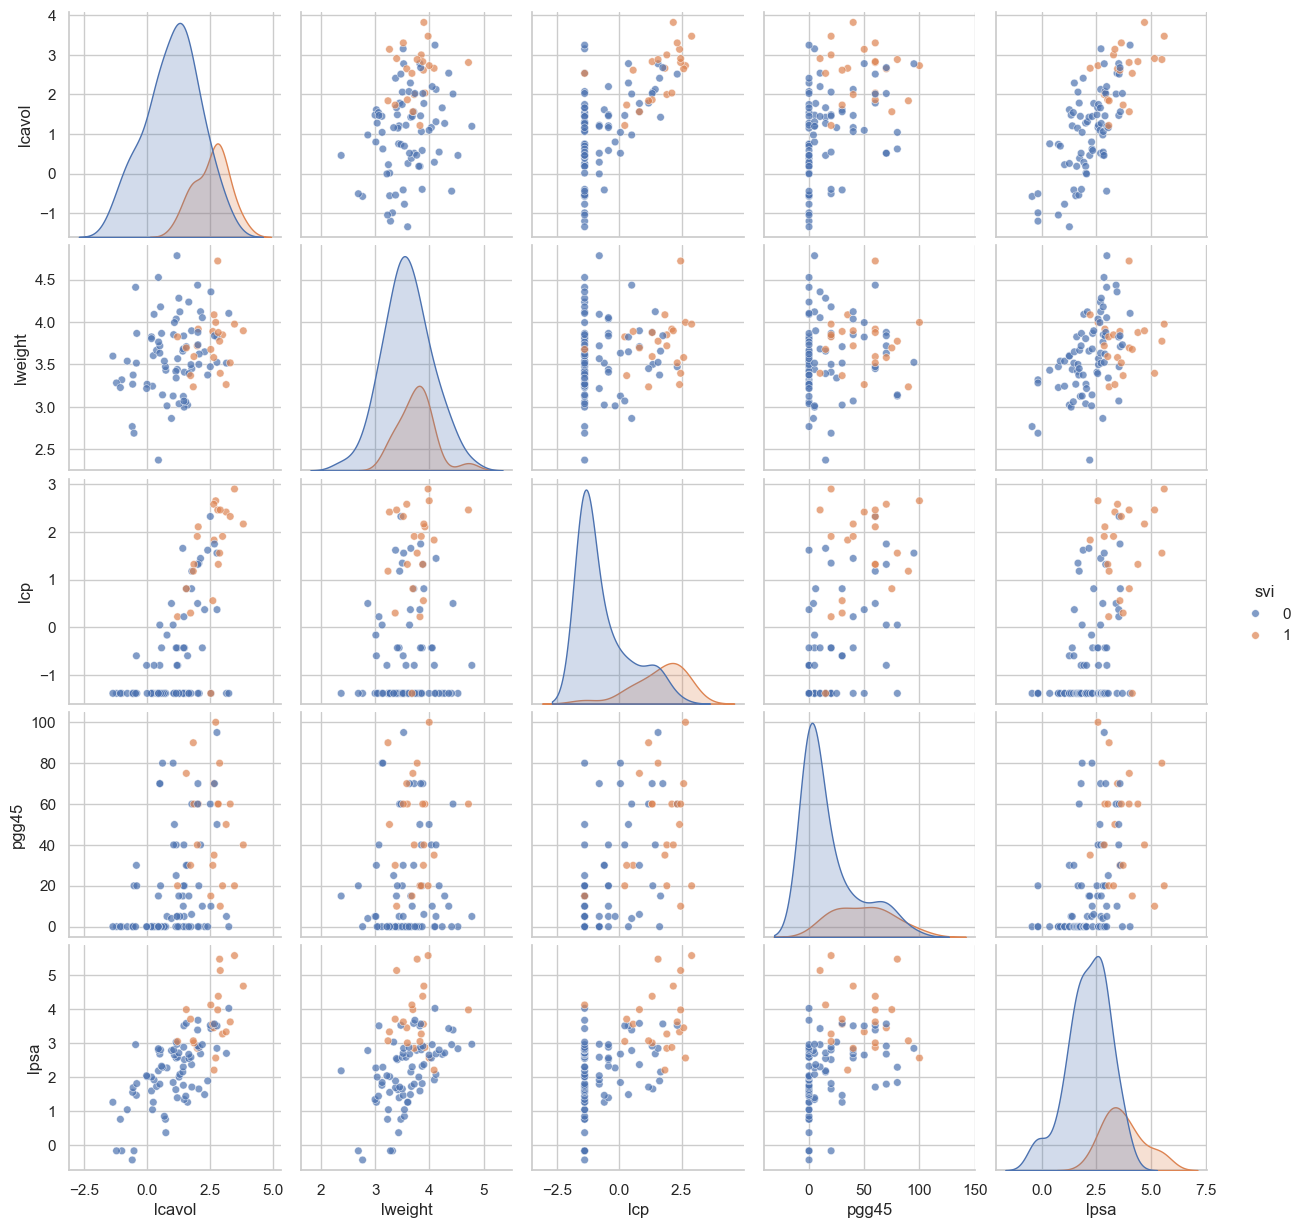

In [12]:
sns.pairplot(df[["lcavol", "lweight", "lcp", "pgg45", "lpsa", "svi"]], hue="svi",
             diag_kind="kde", plot_kws={"alpha": 0.7, "s": 30})
plt.show()

### 4.3 PSA selon les variables cliniques

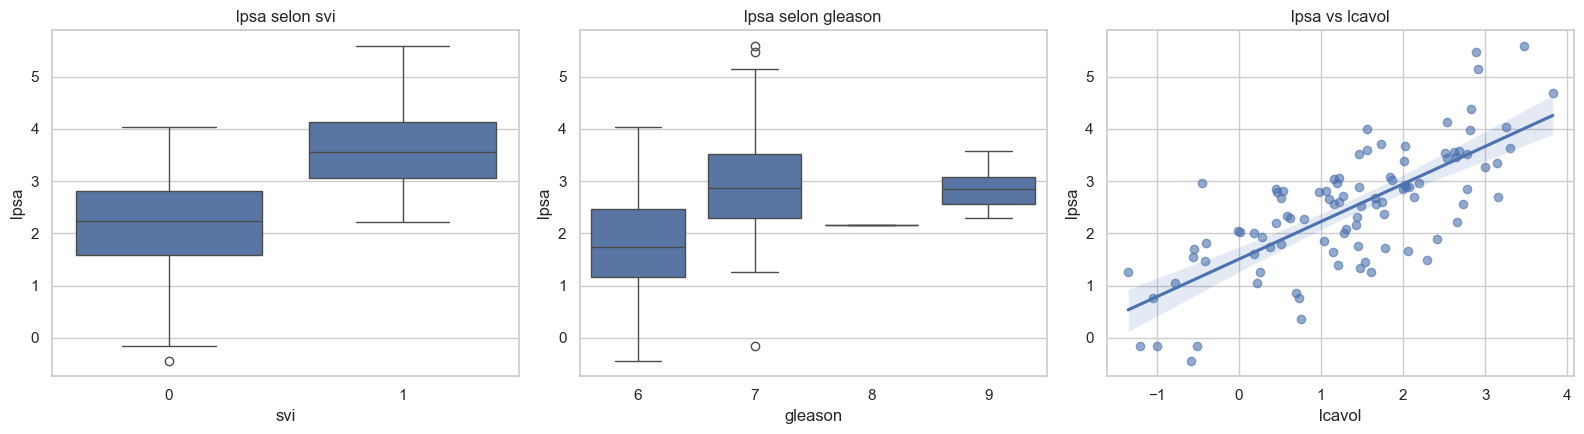

Mann-Whitney lpsa ~ svi : p = 2.66e-08
Kruskal-Wallis lpsa ~ gleason : p = 1.81e-05


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.boxplot(data=df, x="svi", y="lpsa", ax=axes[0]); axes[0].set_title("lpsa selon svi")
sns.boxplot(data=df, x="gleason", y="lpsa", ax=axes[1]); axes[1].set_title("lpsa selon gleason")
sns.regplot(data=df, x="lcavol", y="lpsa", ax=axes[2], scatter_kws={"alpha": .6})
axes[2].set_title("lpsa vs lcavol")
plt.tight_layout(); plt.show()

g0, g1 = df.loc[df.svi == 0, "lpsa"], df.loc[df.svi == 1, "lpsa"]
print("Mann-Whitney lpsa ~ svi : p =", f"{stats.mannwhitneyu(g0, g1).pvalue:.2e}")
print("Kruskal-Wallis lpsa ~ gleason : p =",
      f"{stats.kruskal(*[g['lpsa'] for _, g in df.groupby('gleason')]).pvalue:.2e}")

## 5. Choix de la variable cible

Comme tous les patients ont un cancer, la question « bénin vs malin » n'est **pas** directement modélisable ici. Trois reformulations cohérentes avec l'objectif (éviter des examens invasifs) :

| Option | Cible | Type | Intérêt clinique |
|---|---|---|---|
| A | `lpsa` | régression | usage historique du dataset (Stamey, *ESL* de Hastie et al.) |
| B | `gleason ≥ 7` | classification binaire | cancer **agressif** vs peu agressif → décider entre surveillance active et traitement |
| C | `svi = 1` | classification binaire | cancer **étendu** (invasion des vésicules séminales) |

> Attention : `gleason`, `pgg45`, `svi`, `lcp`, `lcavol` sont mesurés **sur la pièce opératoire**. Pour un modèle qui doit *éviter* une biopsie, les seules variables réellement disponibles avant l'intervention sont surtout `lpsa`, `age` et (par imagerie) `lweight`. C'est un point à discuter dans le rapport.

Option B — gleason ≥ 7 : {1: 62, 0: 35}
Option C — svi = 1     : {0: 76, 1: 21}


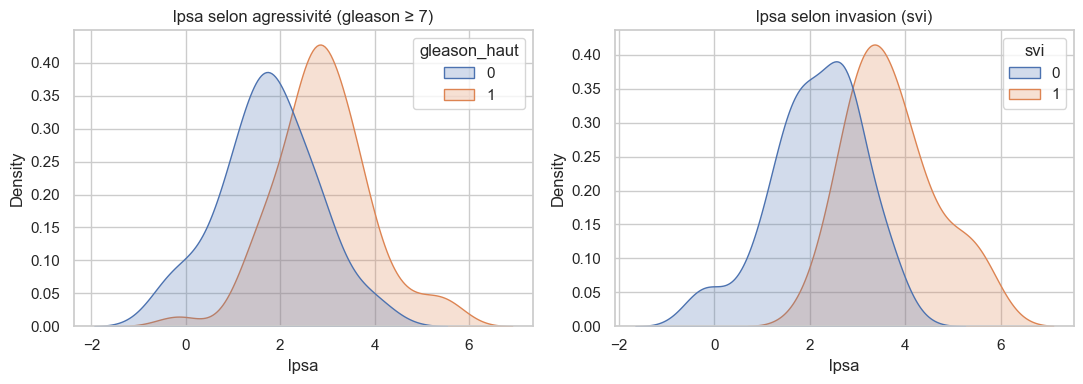

In [14]:
df["gleason_haut"] = (df["gleason"] >= 7).astype(int)
print("Option B — gleason ≥ 7 :", df["gleason_haut"].value_counts().to_dict())
print("Option C — svi = 1     :", df["svi"].value_counts().to_dict())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.kdeplot(data=df, x="lpsa", hue="gleason_haut", fill=True, common_norm=False, ax=axes[0])
axes[0].set_title("lpsa selon agressivité (gleason ≥ 7)")
sns.kdeplot(data=df, x="lpsa", hue="svi", fill=True, common_norm=False, ax=axes[1])
axes[1].set_title("lpsa selon invasion (svi)")
plt.tight_layout(); plt.show()

In [15]:
# Pouvoir discriminant univarié de chaque variable pour les cibles B et C (AUC)
from sklearn.metrics import roc_auc_score
feats = ["lcavol", "lweight", "age", "lbph", "lcp", "pgg45", "lpsa"]
auc = pd.DataFrame({
    "AUC gleason≥7": [roc_auc_score(df["gleason_haut"], df[f]) for f in feats],
    "AUC svi":       [roc_auc_score(df["svi"], df[f]) for f in feats],
}, index=feats)
auc.style.background_gradient(cmap="Greens", vmin=0.5, vmax=1).format("{:.2f}")

,AUC gleason≥7,AUC svi
lcavol,0.80,0.89
lweight,0.60,0.62
age,0.65,0.59
lbph,0.57,0.44
lcp,0.82,0.91
pgg45,1.00,0.83
lpsa,0.80,0.90


Une AUC proche de 0,5 = variable non informative ; proche de 1 = très discriminante. (Pour la cible B, `pgg45` est quasi une fuite d'information car dérivée du même examen que le Gleason.)

## 6. Valeurs aberrantes

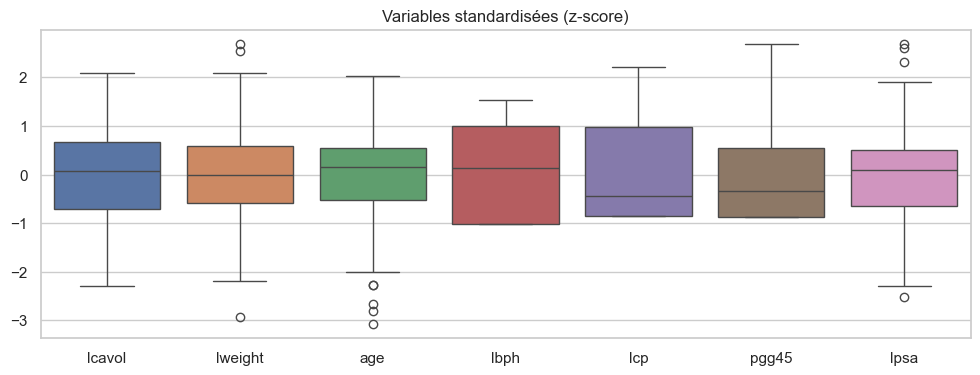

Observations avec |z| > 3 :
    lcavol  lweight  age   lbph    lcp  pgg45   lpsa
18  -0.562    3.268   41 -1.386 -1.386      0  1.558


In [16]:
fig, ax = plt.subplots(figsize=(12, 4))
z = (df[continues] - df[continues].mean()) / df[continues].std()
sns.boxplot(data=z, ax=ax)
ax.set_title("Variables standardisées (z-score)")
plt.show()

out = (z.abs() > 3)
print("Observations avec |z| > 3 :")
print(df[out.any(axis=1)][continues])

Un seul patient dépasse |z| > 3 : le patient n°18, âgé de **41 ans** (la médiane est de 65 ans). La valeur est plausible médicalement, donc on le **conserve**. On peut vérifier son influence sur le modèle (distance de Cook).

## 7. Vérification du découpage train / test

In [17]:
print(df["train"].value_counts())
comp = df.groupby("train")[continues + ["svi", "gleason_haut"]].mean().T
comp.columns = ["test", "train"]
comp["écart"] = comp["train"] - comp["test"]
comp

train
True     67
False    30
Name: count, dtype: int64


,test,train,écart
lcavol,1.432,1.313,-0.118
lweight,3.635,3.626,-0.009
age,61.900,64.746,2.846
lbph,0.165,0.071,-0.093
lcp,-0.102,-0.214,-0.113
pgg45,20.167,26.269,6.102
lpsa,2.537,2.452,-0.084
svi,0.200,0.224,0.024
gleason_haut,0.667,0.627,-0.040


In [18]:
# Test de Kolmogorov-Smirnov : les distributions train et test sont-elles similaires ?
ks = {c: stats.ks_2samp(df.loc[df.train, c], df.loc[~df.train, c]).pvalue for c in continues}
pd.Series(ks, name="p-value KS").to_frame()

,p-value KS
lcavol,0.799
lweight,0.497
age,0.295
lbph,0.989
lcp,0.967
pgg45,0.661
lpsa,0.497


Si toutes les p-values sont > 0,05, le découpage d'origine est représentatif. Avec seulement 97 patients, on privilégiera tout de même la **validation croisée** (k-fold stratifiée) plutôt qu'un unique split.

## 8. Conclusions de l'EDA

1. **Données propres** : 97 patients, 9 variables, aucune valeur manquante ni doublon.
2. **Petit échantillon** (n = 97) → modèles simples (régression logistique / linéaire régularisée), validation croisée, prudence sur la généralisation.
3. **Zéros codés** dans `lbph`, `lcp` (≈ 45 %) et `pgg45` (≈ 36 %) → distributions bimodales ; ajouter des indicateurs binaires.
4. **Multicolinéarité** (`gleason`/`pgg45`, `lcavol`/`lcp`/`svi`) → Ridge / Lasso.
5. **`lcavol`** est la variable la plus liée au PSA et aux marqueurs de gravité.
6. **Cible** : pas de bénin/malin dans les données → reformuler l'objectif (agressivité `gleason ≥ 7`, extension `svi`, ou régression sur `lpsa`), et discuter quelles variables sont réellement disponibles *avant* biopsie.
7. **Déséquilibre de classes** : `svi` 78/22 → métriques adaptées (AUC, F1, rappel), `class_weight="balanced"`.